# Weather Data Analysis & Forecasting

**Project Overview**

This project analyzes historical weather data for Mohali, India, to identify temperature and rainfall patterns and develop models for next-day weather prediction.

The analysis includes exploratory data analysis, temperature forecasting using regression models, rainy-day classification, and an extension using weather data from nearby cities.

In [1251]:
import pandas as pd

## 1. Data Collection and Loading

Historical daily weather data for Mohali was collected for the period 2016–2025. The dataset includes temperature, rainfall, humidity, wind speed, and other weather-related variables.

In [1252]:
df = pd.read_csv("/content/mohali_weather_2016_2025.csv", skiprows=3)

In [1253]:
print(df.columns.tolist())

['time', 'weather_code (wmo code)', 'temperature_2m_mean (°C)', 'temperature_2m_max (°C)', 'temperature_2m_min (°C)', 'precipitation_sum (mm)', 'wind_speed_10m_max (km/h)', 'relative_humidity_2m_mean (%)']


## 2. Data Inspection and Cleaning

The dataset was inspected to understand its structure, data types, and completeness. Missing values, duplicate records, and date formats were examined to ensure the data was suitable for further analysis.

In [1254]:
df.head()

,time,weather_code (wmo code),temperature_2m_mean (°C),temperature_2m_max (°C),temperature_2m_min (°C),precipitation_sum (mm),wind_speed_10m_max (km/h),relative_humidity_2m_mean (%)
0,2016-01-01,3,13.8,21.4,9.5,0.0,8.0,62
1,2016-01-02,3,13.3,21.5,7.5,0.0,12.2,65
2,2016-01-03,2,13.4,22.0,8.1,0.0,16.7,69
3,2016-01-04,3,13.6,19.1,8.5,0.0,6.4,74
4,2016-01-05,3,16.3,24.0,11.7,0.0,9.8,66


In [1255]:
df.shape

(3653, 8)

In [1256]:
df.dtypes

,0
time,object
weather_code (wmo code),int64
temperature_2m_mean (°C),float64
temperature_2m_max (°C),float64
temperature_2m_min (°C),float64
precipitation_sum (mm),float64
wind_speed_10m_max (km/h),float64
relative_humidity_2m_mean (%),int64


In [1257]:
print(df.columns.tolist())
print(df["time"].head(10))

['time', 'weather_code (wmo code)', 'temperature_2m_mean (°C)', 'temperature_2m_max (°C)', 'temperature_2m_min (°C)', 'precipitation_sum (mm)', 'wind_speed_10m_max (km/h)', 'relative_humidity_2m_mean (%)']
0    2016-01-01
1    2016-01-02
2    2016-01-03
3    2016-01-04
4    2016-01-05
5    2016-01-06
6    2016-01-07
7    2016-01-08
8    2016-01-09
9    2016-01-10
Name: time, dtype: object


In [1258]:
df["time"] = pd.to_datetime(df["time"], format="%Y-%m-%d")

In [1259]:
df.dtypes

,0
time,datetime64[ns]
weather_code (wmo code),int64
temperature_2m_mean (°C),float64
temperature_2m_max (°C),float64
temperature_2m_min (°C),float64
precipitation_sum (mm),float64
wind_speed_10m_max (km/h),float64
relative_humidity_2m_mean (%),int64


In [1260]:
df.isna().sum()

,0
time,0
weather_code (wmo code),0
temperature_2m_mean (°C),0
temperature_2m_max (°C),0
temperature_2m_min (°C),0
precipitation_sum (mm),0
wind_speed_10m_max (km/h),0
relative_humidity_2m_mean (%),0


In [1261]:
df["time"].duplicated().sum()

np.int64(0)

In [1262]:
df.describe()

,time,weather_code (wmo code),temperature_2m_mean (°C),temperature_2m_max (°C),temperature_2m_min (°C),precipitation_sum (mm),wind_speed_10m_max (km/h),relative_humidity_2m_mean (%)
count,3653,3653.000000,3653.000000,3653.000000,3653.000000,3653.000000,3653.000000,3653.000000
mean,2020-12-31 00:00:00,24.205311,24.496469,30.378128,19.731618,2.017438,13.465508,64.858472
min,2016-01-01 00:00:00,0.000000,8.600000,11.900000,4.400000,0.000000,4.500000,18.000000
25%,2018-07-02 00:00:00,1.000000,18.000000,25.300000,13.000000,0.000000,9.800000,53.000000
50%,2020-12-31 00:00:00,3.000000,26.800000,31.900000,21.000000,0.000000,12.800000,69.000000
75%,2023-07-02 00:00:00,51.000000,30.200000,35.000000,26.500000,1.000000,16.300000,78.000000
max,2025-12-31 00:00:00,65.000000,39.100000,45.800000,32.800000,162.500000,43.600000,96.000000
std,NaN,26.649114,7.089293,6.853298,7.168158,7.685054,4.625390,16.782856


In [1263]:
df.describe(include="number").T

,count,mean,std,min,25%,50%,75%,max
weather_code (wmo code),3653.0,24.205311,26.649114,0.0,1.0,3.0,51.0,65.0
temperature_2m_mean (°C),3653.0,24.496469,7.089293,8.6,18.0,26.8,30.2,39.1
temperature_2m_max (°C),3653.0,30.378128,6.853298,11.9,25.3,31.9,35.0,45.8
temperature_2m_min (°C),3653.0,19.731618,7.168158,4.4,13.0,21.0,26.5,32.8
precipitation_sum (mm),3653.0,2.017438,7.685054,0.0,0.0,0.0,1.0,162.5
wind_speed_10m_max (km/h),3653.0,13.465508,4.625390,4.5,9.8,12.8,16.3,43.6
relative_humidity_2m_mean (%),3653.0,64.858472,16.782856,18.0,53.0,69.0,78.0,96.0


In [1264]:
expected_days = pd.date_range(start="2016-01-01", end="2025-12-31")

len(expected_days), len(df)

(3653, 3653)

In [1265]:
df["time"].diff().value_counts()

,count
time,
1 days,3652


In [1266]:
df = df.rename(columns={
    "time": "date",
    "weather_code (wmo code)": "weather_code",
    "temperature_2m_mean (°C)": "temp_mean",
    "temperature_2m_max (°C)": "temp_max",
    "temperature_2m_min (°C)": "temp_min",
    "precipitation_sum (mm)": "rainfall",
    "wind_speed_10m_max (km/h)": "wind_speed",
    "relative_humidity_2m_mean (%)": "humidity"
})

In [1267]:
df.head()

,date,weather_code,temp_mean,temp_max,temp_min,rainfall,wind_speed,humidity
0,2016-01-01,3,13.8,21.4,9.5,0.0,8.0,62
1,2016-01-02,3,13.3,21.5,7.5,0.0,12.2,65
2,2016-01-03,2,13.4,22.0,8.1,0.0,16.7,69
3,2016-01-04,3,13.6,19.1,8.5,0.0,6.4,74
4,2016-01-05,3,16.3,24.0,11.7,0.0,9.8,66


In [1268]:
df = df.sort_values("date").reset_index(drop=True)

In [1269]:
df[["date", "temp_mean", "rainfall"]].head()

,date,temp_mean,rainfall
0,2016-01-01,13.8,0.0
1,2016-01-02,13.3,0.0
2,2016-01-03,13.4,0.0
3,2016-01-04,13.6,0.0
4,2016-01-05,16.3,0.0


In [1270]:
df[["date", "temp_mean", "temp_max", "temp_min"]].head()

,date,temp_mean,temp_max,temp_min
0,2016-01-01,13.8,21.4,9.5
1,2016-01-02,13.3,21.5,7.5
2,2016-01-03,13.4,22.0,8.1
3,2016-01-04,13.6,19.1,8.5
4,2016-01-05,16.3,24.0,11.7


In [1271]:
import os

os.makedirs("results/figures", exist_ok=True)

## 3. Exploratory Data Analysis (EDA)

Exploratory data analysis was performed to understand the distribution and variation of weather variables in Mohali. Temperature, rainfall, humidity, and wind patterns were examined to identify trends, seasonal changes, and relationships between variables.

### Calendar Features

In [1272]:
df["month"] = df["date"].dt.month

In [1273]:
df[["date", "month"]].head()

,date,month
0,2016-01-01,1
1,2016-01-02,1
2,2016-01-03,1
3,2016-01-04,1
4,2016-01-05,1


### Monthly Temperature Analysis

In [1274]:
monthly_temp = df.groupby("month")["temp_mean"].mean()
monthly_temp

,temp_mean
month,
1,13.033871
2,17.124028
3,22.370968
4,28.670667
5,31.659355
6,32.639667
7,30.416774
8,29.640000
9,28.957000


### Monthly Temperature Trend

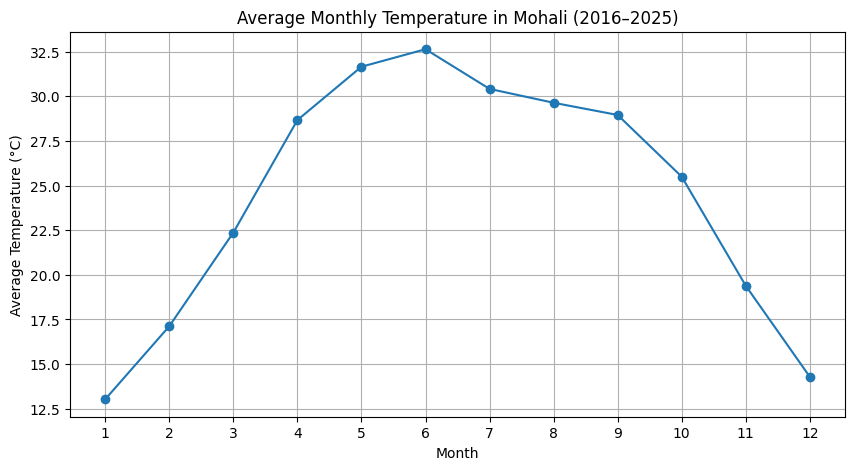

In [1275]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(monthly_temp.index, monthly_temp.values, marker="o")
plt.xlabel("Month")
plt.ylabel("Average Temperature (°C)")
plt.title("Average Monthly Temperature in Mohali (2016–2025)")
plt.xticks(range(1, 13))
plt.grid(True)
plt.savefig("results/figures/average_monthly_temperature_in_mohali.png",
            dpi=300, bbox_inches="tight")
plt.show()

**Observation:** The average temperature increases from January to June, reaching the highest value in June (about 32.4°C). It then decreases until December. This shows a clear seasonal pattern in Mohali.

### Yearly Temperature Variation

In [1276]:
df["year"] = df["date"].dt.year
yearly_temp = df.groupby("year")["temp_mean"].mean()
yearly_temp

,temp_mean
year,
2016,25.260929
2017,24.959452
2018,24.420822
2019,24.100274
2020,24.113934
2021,24.334795
2022,24.966575
2023,24.010685
2024,24.476503


### Yearly Temperature Trend

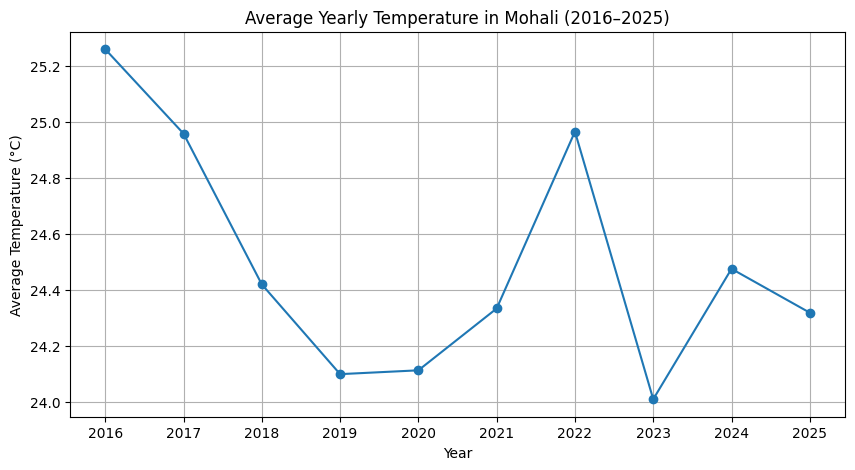

In [1277]:
plt.figure(figsize=(10, 5))
plt.plot(yearly_temp.index, yearly_temp.values, marker="o")
plt.xlabel("Year")
plt.ylabel("Average Temperature (°C)")
plt.title("Average Yearly Temperature in Mohali (2016–2025)")
plt.xticks(yearly_temp.index)
plt.grid(True)
plt.savefig("results/figures/yearly_temperature_in_mohali.png",
            dpi=300, bbox_inches="tight")
plt.show()

**Observation:** The yearly average temperature varies slightly from year to year. It decreases from 2016 to 2019 and then shows fluctuations, with a noticeable increase in 2022 followed by a decrease in 2023.

### Monthly Temperature Range

In [1278]:
monthly_max = df.groupby("month")["temp_max"].mean()
monthly_min = df.groupby("month")["temp_min"].mean()
monthly_max, monthly_min

(month
 1     18.625161
 2     23.796466
 3     29.288710
 4     36.131667
 5     38.239355
 6     37.839667
 7     33.650968
 8     32.849355
 9     33.105333
 10    32.429032
 11    27.008000
 12    21.406129
 Name: temp_max, dtype: float64,
 month
 1      9.208065
 2     12.045583
 3     16.477742
 4     21.644667
 5     25.261613
 6     27.551333
 7     27.642903
 8     27.067742
 9     25.619667
 10    20.050000
 11    14.126667
 12     9.737097
 Name: temp_min, dtype: float64)

### Monthly Maximum and Minimum Temperature

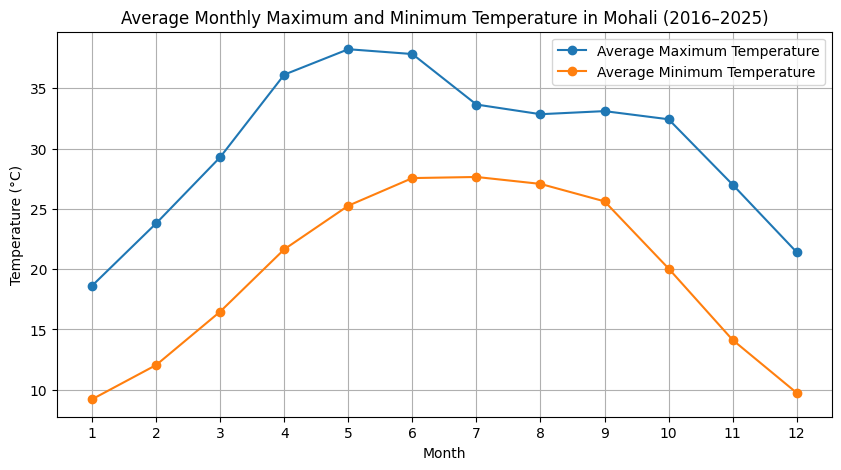

In [1279]:
plt.figure(figsize=(10, 5))

plt.plot(monthly_max.index, monthly_max.values, marker="o", label="Average Maximum Temperature")
plt.plot(monthly_min.index, monthly_min.values, marker="o", label="Average Minimum Temperature")

plt.xlabel("Month")
plt.ylabel("Temperature (°C)")
plt.title("Average Monthly Maximum and Minimum Temperature in Mohali (2016–2025)")
plt.xticks(range(1, 13))
plt.legend()
plt.grid(True)
plt.savefig("results/figures/average_monthly_maximum_and_minimum_temperature_in_mohali.png",
            dpi=300, bbox_inches="tight")
plt.show()

**Observation:** Average maximum and minimum temperatures both show a clear seasonal pattern. They increase toward the summer months and decrease toward winter. The highest temperatures occur around May–June, while the lowest values occur during the winter months.

### Seasonal Temperature Analysis

In [1280]:
season_map = {
    12: "Winter",
    1: "Winter",
    2: "Winter",
    3: "Spring",
    4: "Spring",
    5: "Spring",
    6: "Summer",
    7: "Summer",
    8: "Summer",
    9: "Autumn",
    10: "Autumn",
    11: "Autumn"
}

df["season"] = df["month"].map(season_map)
df[["date", "month", "season"]].head(15)

,date,month,season
0,2016-01-01,1,Winter
1,2016-01-02,1,Winter
2,2016-01-03,1,Winter
3,2016-01-04,1,Winter
4,2016-01-05,1,Winter
5,2016-01-06,1,Winter
6,2016-01-07,1,Winter
7,2016-01-08,1,Winter
8,2016-01-09,1,Winter
9,2016-01-10,1,Winter


### Average Temperature by Season

In [1281]:
seasonal_temp = df.groupby("season")["temp_mean"].mean()
seasonal_temp

,temp_mean
season,
Autumn,24.625165
Spring,27.555000
Summer,30.879891
Winter,14.747065


**Observation:** Summer has the highest average temperature (about 30.9°C), while winter has the lowest (about 14.7°C). Spring and autumn have intermediate temperatures, showing a clear seasonal pattern.

### Seasonal Temperature Visualization

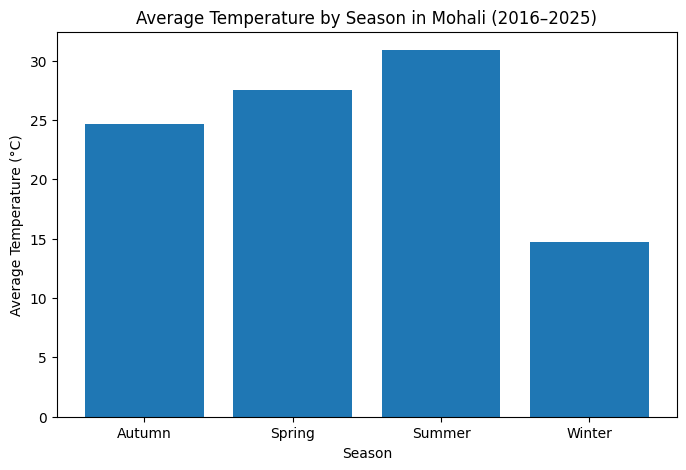

In [1282]:
plt.figure(figsize=(8, 5))

plt.bar(seasonal_temp.index, seasonal_temp.values)

plt.xlabel("Season")
plt.ylabel("Average Temperature (°C)")
plt.title("Average Temperature by Season in Mohali (2016–2025)")
plt.savefig("results/figures/average_temperature_by_season.png",
            dpi=300, bbox_inches="tight")
plt.show()

### Rainfall Analysis

In [1283]:
df["rainfall"].describe()

,rainfall
count,3653.000000
mean,2.017438
std,7.685054
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,162.500000


In [1284]:
rainy_days = (df["rainfall"] > 0).sum()
rainy_days

np.int64(1548)

In [1285]:
rainy_percentage = (rainy_days / len(df)) * 100
rainy_percentage

np.float64(42.37612920886942)

**Observation**: Out of 3,653 days, 1,548 days had measurable rainfall. This means about 42.4% of the days were rainy, while the remaining days had no measurable rainfall.

### Daily Rainfall Distribution

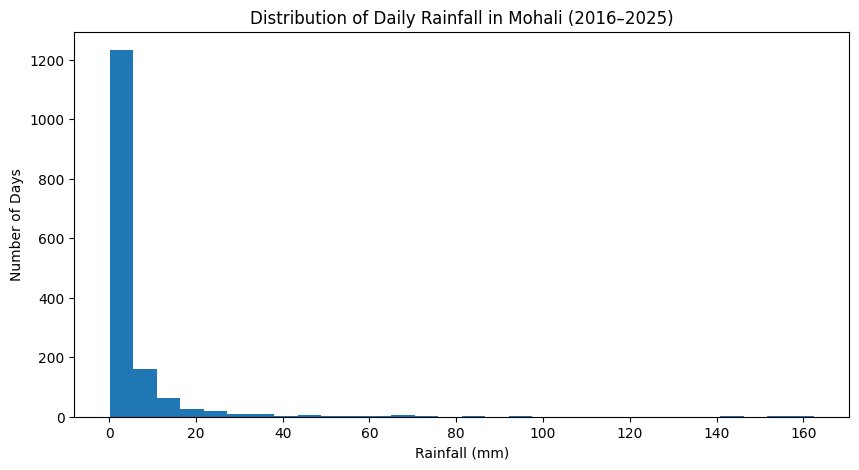

In [1286]:
plt.figure(figsize=(10, 5))

plt.hist(df.loc[df["rainfall"] > 0, "rainfall"], bins=30)

plt.xlabel("Rainfall (mm)")
plt.ylabel("Number of Days")
plt.title("Distribution of Daily Rainfall in Mohali (2016–2025)")
plt.savefig("results/figures/daily_rainfall_distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()

**Observation:** Daily rainfall is concentrated at the lower rainfall values, while higher rainfall amounts occur much less frequently. The distribution has a long tail toward heavier rainfall events.

### Monthly Rainfall Pattern

In [1287]:
monthly_rainfall = df.groupby("month")["rainfall"].mean()
monthly_rainfall

,rainfall
month,
1,1.644516
2,1.099293
3,1.098710
4,0.610333
5,1.085806
6,1.730000
7,6.510000
8,5.670968
9,3.564333


**Observation:** Average daily rainfall is highest during July and August and remains relatively high in September. Rainfall is much lower during the other months, especially October and November.

### Monthly Rainfall Visualization

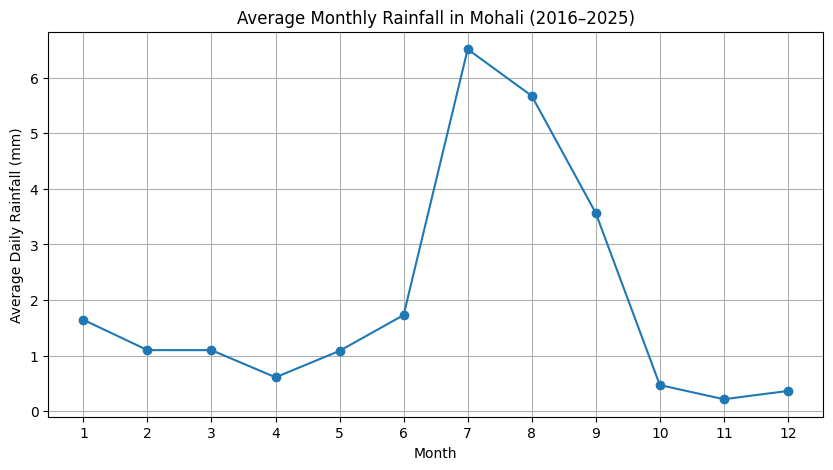

In [1288]:
plt.figure(figsize=(10, 5))

plt.plot(monthly_rainfall.index, monthly_rainfall.values, marker="o")

plt.xlabel("Month")
plt.ylabel("Average Daily Rainfall (mm)")
plt.title("Average Monthly Rainfall in Mohali (2016–2025)")
plt.xticks(range(1, 13))
plt.grid(True)
plt.savefig("results/figures/average_monthly_rainfall_in_mohali.png",
            dpi=300, bbox_inches="tight")
plt.show()

**Observation:** Average daily rainfall is highest in July and August, with July showing the highest value. Rainfall decreases after September and remains low during October to December.

### Seasonal Rainfall Analysis

In [1289]:
seasonal_rainfall = df.groupby("season")["rainfall"].mean()
seasonal_rainfall

,rainfall
season,
Autumn,1.406813
Spring,0.935109
Summer,4.668587
Winter,1.034441


**Observation:** Summer has the highest average daily rainfall (about 4.7 mm), while spring has the lowest (about 0.9 mm). Rainfall is much higher in summer than in the other seasons.

### Monthly Humidity Analysis

In [1290]:
monthly_humidity = df.groupby("month")["humidity"].mean()
monthly_humidity

,humidity
month,
1,79.232258
2,68.130742
3,56.219355
4,39.356667
5,41.567742
6,53.120000
7,76.319355
8,81.241935
9,77.273333


### Monthly Humidity Visualization

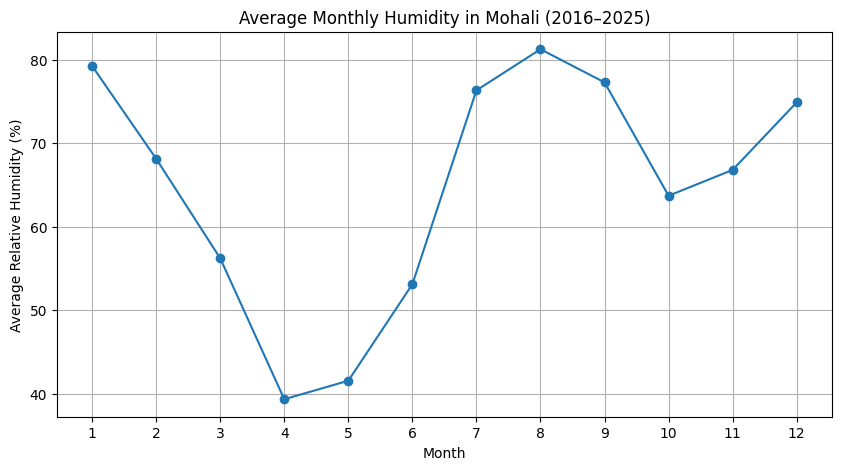

In [1291]:
plt.figure(figsize=(10, 5))

plt.plot(monthly_humidity.index, monthly_humidity.values, marker="o")

plt.xlabel("Month")
plt.ylabel("Average Relative Humidity (%)")
plt.title("Average Monthly Humidity in Mohali (2016–2025)")
plt.xticks(range(1, 13))
plt.grid(True)
plt.savefig("results/figures/average_monthly_humidity_in_mohali.png",
            dpi=300, bbox_inches="tight")
plt.show()

Observation: Relative humidity in Mohali shows a clear seasonal pattern. It is lowest in April and highest in August, consistent with the dry pre-monsoon period and humid monsoon season.

### Wind Speed Analysis

In [1292]:
monthly_wind = df.groupby("month")["wind_speed"].mean()
monthly_wind

,wind_speed
month,
1,11.951613
2,14.518728
3,15.747097
4,17.163333
5,17.169355
6,15.112000
7,12.307097
8,11.569677
9,11.896333


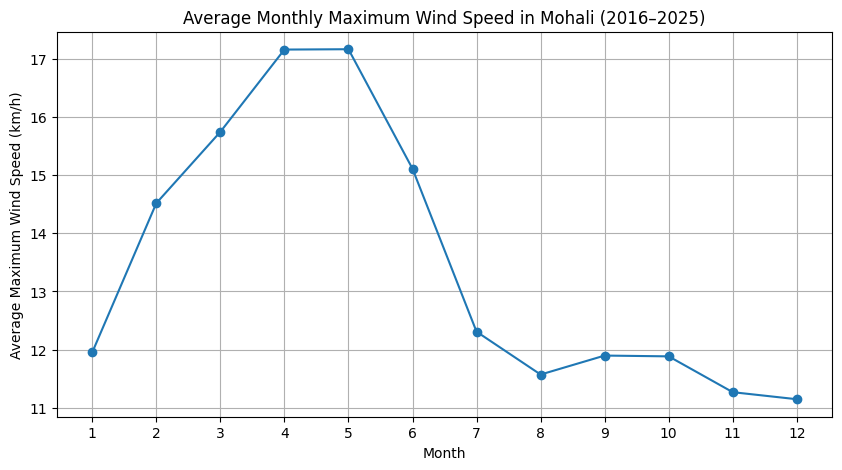

In [1293]:
plt.figure(figsize=(10, 5))

plt.plot(monthly_wind.index, monthly_wind.values, marker="o")

plt.xlabel("Month")
plt.ylabel("Average Maximum Wind Speed (km/h)")
plt.title("Average Monthly Maximum Wind Speed in Mohali (2016–2025)")
plt.xticks(range(1, 13))
plt.grid(True)
plt.savefig("results/figures/average_monthly_maximum_wind_speed_in_mohali.png",
            dpi=300, bbox_inches="tight")
plt.show()

Observation: Mohali's average daily maximum wind speed varies seasonally, reaching its highest levels in April–May and lowest levels in late autumn and winter.

### Correlation Analysis

In [1294]:
weather_corr = df[[
    "temp_mean",
    "rainfall",
    "humidity",
    "wind_speed"
]].corr()

weather_corr

,temp_mean,rainfall,humidity,wind_speed
temp_mean,1.000000,0.051354,-0.424026,0.232105
rainfall,0.051354,1.000000,0.251754,0.041154
humidity,-0.424026,0.251754,1.000000,-0.490218
wind_speed,0.232105,0.041154,-0.490218,1.000000


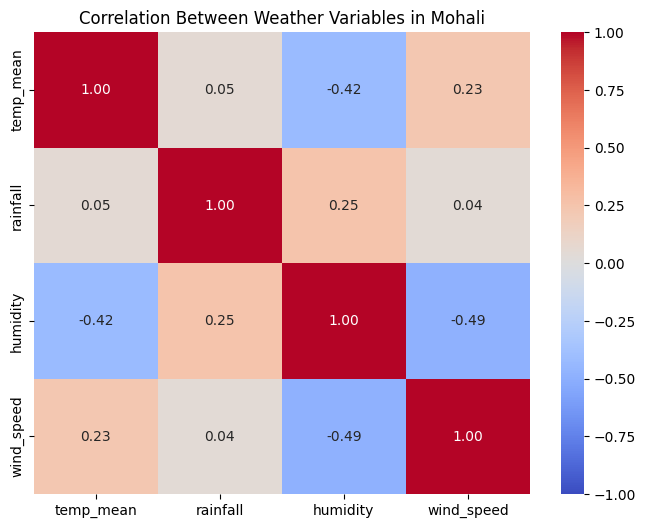

In [1295]:
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    weather_corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Between Weather Variables in Mohali")
plt.savefig("results/figures/correlation_between_weather_variables_in_mohali.png",
            dpi=300, bbox_inches="tight")
plt.show()

Temperature vs. humidity (−0.42): Higher temperatures tend to be associated with lower humidity.
Humidity vs. wind speed (−0.49): Higher humidity tends to be associated with lower maximum wind speeds.
Rainfall vs. humidity (+0.25): Higher rainfall tends to be associated with higher humidity, but the relationship is weak.

In [1296]:
print(df.columns.tolist())

['date', 'weather_code', 'temp_mean', 'temp_max', 'temp_min', 'rainfall', 'wind_speed', 'humidity', 'month', 'year', 'season']


In [1297]:
df["date"] = pd.to_datetime(df["date"], dayfirst=True)

print(df["date"].dtype)
print(df["date"].head())

datetime64[ns]
0   2016-01-01
1   2016-01-02
2   2016-01-03
3   2016-01-04
4   2016-01-05
Name: date, dtype: datetime64[ns]


Arranging the weather data chronologically

In [1298]:
df = df.sort_values("date").reset_index(drop=True)

print(df[["date", "temp_mean"]].head())
print("\nTotal records:", len(df))
print("Duplicate dates:", df["date"].duplicated().sum())

        date  temp_mean
0 2016-01-01       13.8
1 2016-01-02       13.3
2 2016-01-03       13.4
3 2016-01-04       13.6
4 2016-01-05       16.3

Total records: 3653
Duplicate dates: 0


## 4. Feature Engineering

Additional features were created from the weather data to help the models learn temporal patterns. These features include previous-day weather values, calendar-based variables, and the next-day temperature target.

In [1299]:
df["target_temp_next_day"] = df["temp_mean"].shift(-1)

print(df[["date", "temp_mean", "target_temp_next_day"]].head())

        date  temp_mean  target_temp_next_day
0 2016-01-01       13.8                  13.3
1 2016-01-02       13.3                  13.4
2 2016-01-03       13.4                  13.6
3 2016-01-04       13.6                  16.3
4 2016-01-05       16.3                  15.9


In [1300]:
df["temp_previous_day"] = df["temp_mean"].shift(1)

print(df[["date", "temp_mean", "temp_previous_day"]].head())

        date  temp_mean  temp_previous_day
0 2016-01-01       13.8                NaN
1 2016-01-02       13.3               13.8
2 2016-01-03       13.4               13.3
3 2016-01-04       13.6               13.4
4 2016-01-05       16.3               13.6


In [1301]:
df["temp_2_days_ago"] = df["temp_mean"].shift(2)

print(df[["date", "temp_mean", "temp_previous_day", "temp_2_days_ago"]].head(7))

        date  temp_mean  temp_previous_day  temp_2_days_ago
0 2016-01-01       13.8                NaN              NaN
1 2016-01-02       13.3               13.8              NaN
2 2016-01-03       13.4               13.3             13.8
3 2016-01-04       13.6               13.4             13.3
4 2016-01-05       16.3               13.6             13.4
5 2016-01-06       15.9               16.3             13.6
6 2016-01-07       16.1               15.9             16.3


In [1302]:
df["month"] = df["date"].dt.month

print(df[["date", "month"]].head(10))

        date  month
0 2016-01-01      1
1 2016-01-02      1
2 2016-01-03      1
3 2016-01-04      1
4 2016-01-05      1
5 2016-01-06      1
6 2016-01-07      1
7 2016-01-08      1
8 2016-01-09      1
9 2016-01-10      1


In [1303]:
print(df.columns.tolist())

['date', 'weather_code', 'temp_mean', 'temp_max', 'temp_min', 'rainfall', 'wind_speed', 'humidity', 'month', 'year', 'season', 'target_temp_next_day', 'temp_previous_day', 'temp_2_days_ago']


In [1304]:
print(df[[
    "date",
    "temp_mean",
    "target_temp_next_day",
    "temp_previous_day",
    "temp_2_days_ago",
    "month"
]].head())

        date  temp_mean  target_temp_next_day  temp_previous_day  \
0 2016-01-01       13.8                  13.3                NaN   
1 2016-01-02       13.3                  13.4               13.8   
2 2016-01-03       13.4                  13.6               13.3   
3 2016-01-04       13.6                  16.3               13.4   
4 2016-01-05       16.3                  15.9               13.6   

   temp_2_days_ago  month  
0              NaN      1  
1              NaN      1  
2             13.8      1  
3             13.3      1  
4             13.4      1  


In [1305]:
features = [
    "temp_mean",
    "temp_max",
    "temp_min",
    "rainfall",
    "wind_speed",
    "humidity",
    "temp_previous_day",
    "temp_2_days_ago",
    "month"
]

target = "target_temp_next_day"

print("Number of features:", len(features))
print("Target:", target)

Number of features: 9
Target: target_temp_next_day


In [1306]:
model_df = df[features + [target]].dropna().copy()

print("Original records:", len(df))
print("Records for modelling:", len(model_df))
print("Missing values:", model_df.isna().sum().sum())

Original records: 3653
Records for modelling: 3650
Missing values: 0


## 5. Next-Day Temperature Forecasting

Regression models were developed to predict the next day's mean temperature using historical weather observations and engineered features. The models were evaluated using a chronological train-test split to preserve the time order of the data.

In [1307]:
X = model_df[features]
y = model_df[target]

split_index = int(len(model_df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training period:", df.loc[model_df.index[0], "date"], "to",
      df.loc[model_df.index[split_index - 1], "date"])
print("Testing starts:", df.loc[model_df.index[split_index], "date"])

Training records: 2920
Testing records: 730
Training period: 2016-01-03 00:00:00 to 2023-12-31 00:00:00
Testing starts: 2024-01-01 00:00:00


In [1308]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

baseline_predictions = X_test["temp_mean"]

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))

print("Baseline MAE:", round(baseline_mae, 2), "°C")
print("Baseline RMSE:", round(baseline_rmse, 2), "°C")

Baseline MAE: 0.8 °C
Baseline RMSE: 1.09 °C


In [1309]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))

print("Linear Regression MAE:", round(linear_mae, 2), "°C")
print("Linear Regression RMSE:", round(linear_rmse, 2), "°C")

Linear Regression MAE: 0.77 °C
Linear Regression RMSE: 1.08 °C


### Linear Regression — Results and Interpretation

Linear Regression was trained on historical weather data from 2016 to 2023 and evaluated on data from 2024 to 2025.

- MAE: 0.77°C
- RMSE: 1.08°C

The baseline model had an MAE of 0.80°C and an RMSE of 1.09°C. Linear Regression therefore performed slightly better, reducing both prediction errors. However, the improvement was small, suggesting that the baseline is already effective for next-day temperature prediction.

In [1310]:
comparison = pd.DataFrame({
    "Actual_Temperature": y_test,
    "Predicted_Temperature": linear_predictions
})

print(comparison.head(10).round(2))

      Actual_Temperature  Predicted_Temperature
2922                11.6                  11.89
2923                11.6                  11.61
2924                10.5                  11.78
2925                10.0                  10.60
2926                10.2                  10.03
2927                10.8                  10.67
2928                10.4                  10.61
2929                10.3                  10.65
2930                10.5                  10.56
2931                 9.7                  10.39


### Actual vs Predicted Temperature

The comparison shows that Linear Regression predicts next-day temperatures reasonably closely for many test observations. Some predictions have very small errors, while others show larger differences.

This demonstrates why model performance should be evaluated across the entire test dataset using MAE and RMSE, rather than judging the model from only a few predictions.

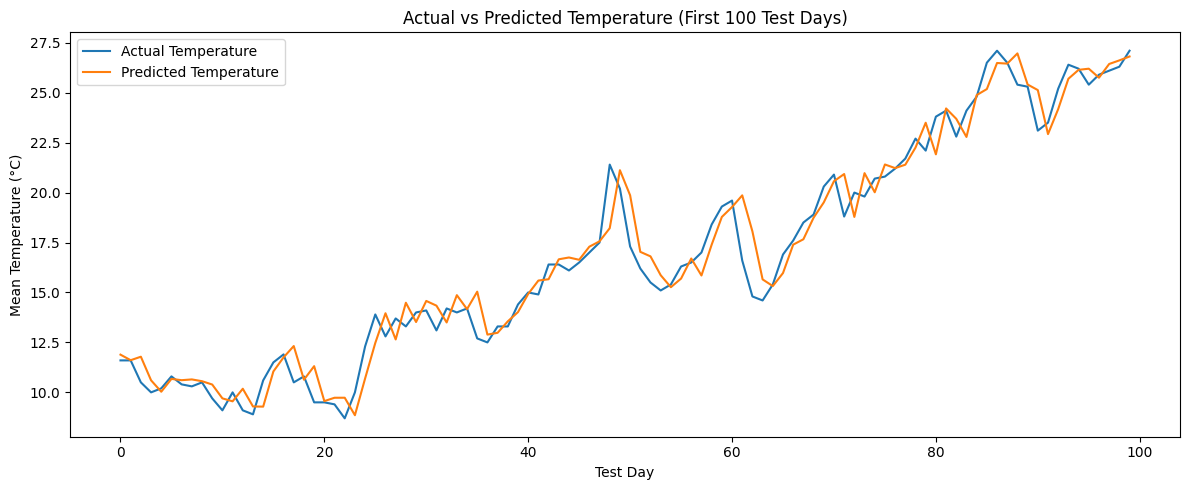

In [1311]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    y_test.iloc[:100].values,
    label="Actual Temperature"
)

plt.plot(
    linear_predictions[:100],
    label="Predicted Temperature"
)

plt.title("Actual vs Predicted Temperature (First 100 Test Days)")
plt.xlabel("Test Day")
plt.ylabel("Mean Temperature (°C)")
plt.legend()
plt.tight_layout()
plt.savefig("results/figures/actual_vs_predicted_temperature.png",
            dpi=300, bbox_inches="tight")
plt.show()

### Actual vs Predicted Temperature — Graph Interpretation

The graph compares actual and predicted mean temperatures for the first 100 test days. The predicted temperatures generally follow the actual temperature trend. However, differences occur during some rapid temperature changes.

This suggests that Linear Regression captures the overall pattern reasonably well but cannot perfectly predict every daily fluctuation. The MAE of 0.77°C and RMSE of 1.08°C quantify its prediction errors across the complete test dataset.

In [1312]:
from sklearn.metrics import r2_score

linear_r2 = r2_score(y_test, linear_predictions)

print("Linear Regression R²:", round(linear_r2, 3))

Linear Regression R²: 0.978


### Linear Regression — R² Score

The Linear Regression model achieved an R² score of 0.978 on the test dataset. This indicates that the model explains approximately 97.8% of the variation in actual next-day mean temperatures. Combined with an MAE of 0.77°C and an RMSE of 1.08°C, this suggests strong predictive performance on the test data.

In [1313]:
results = pd.DataFrame([
    {
        "Model": "Baseline",
        "MAE": baseline_mae,
        "RMSE": baseline_rmse,
        "R2": r2_score(y_test, baseline_predictions)
    },
    {
        "Model": "Linear Regression",
        "MAE": linear_mae,
        "RMSE": linear_rmse,
        "R2": linear_r2
    }
])

print(results.round(3))

               Model    MAE   RMSE     R2
0           Baseline  0.801  1.094  0.977
1  Linear Regression  0.773  1.081  0.978


### Baseline vs Linear Regression

Linear Regression performed slightly better than the baseline model.

- The MAE decreased from 0.801°C to 0.773°C.
- The RMSE decreased from 1.094°C to 1.081°C.
- The R² increased from 0.977 to 0.978.

These results indicate a small improvement in next-day temperature prediction. The baseline model was already effective, so we need to compare additional machine-learning models to determine whether they provide further improvement.

Training a decision tree model

In [1314]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

tree_model = DecisionTreeRegressor(
    max_depth=5,
    random_state=42
)

tree_model.fit(X_train, y_train)

tree_predictions = tree_model.predict(X_test)

tree_mae = mean_absolute_error(y_test, tree_predictions)
tree_rmse = np.sqrt(mean_squared_error(y_test, tree_predictions))
tree_r2 = r2_score(y_test, tree_predictions)

print("Decision Tree MAE:", round(tree_mae, 3))
print("Decision Tree RMSE:", round(tree_rmse, 3))
print("Decision Tree R²:", round(tree_r2, 3))

Decision Tree MAE: 0.902
Decision Tree RMSE: 1.183
Decision Tree R²: 0.973


Decision Tree Regression — Results and Interpretation

The Decision Tree Regressor, with a maximum depth of 5, achieved an MAE of 0.902°C, an RMSE of 1.183°C, and an R² score of 0.973.

Compared with Linear Regression, the Decision Tree had higher prediction errors and a slightly lower R² score. Therefore, it did not improve next-day temperature prediction on the test dataset with the selected parameters.

Training the random forest model

In [1315]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

forest_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

forest_model.fit(X_train, y_train)

forest_predictions = forest_model.predict(X_test)

forest_mae = mean_absolute_error(y_test, forest_predictions)
forest_rmse = np.sqrt(mean_squared_error(y_test, forest_predictions))
forest_r2 = r2_score(y_test, forest_predictions)

print("Random Forest MAE:", round(forest_mae, 3))
print("Random Forest RMSE:", round(forest_rmse, 3))
print("Random Forest R²:", round(forest_r2, 3))

Random Forest MAE: 0.828
Random Forest RMSE: 1.098
Random Forest R²: 0.977


Random Forest Regression — Results and Interpretation

The Random Forest Regressor, using 100 trees and a maximum depth of 10, achieved an MAE of 0.828°C, an RMSE of 1.098°C, and an R² score of 0.977.

Random Forest performed better than the Decision Tree but did not outperform Linear Regression or the baseline model. This indicates that the ensemble model did not provide an improvement in next-day temperature prediction with the selected parameters.

## 6. Regression Model Evaluation and Comparison

The performance of the regression models was evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the coefficient of determination (R²). These metrics were compared to identify the model that best predicts next-day mean temperature.

In [1316]:
results = pd.DataFrame([
    {
        "Model": "Baseline",
        "MAE": baseline_mae,
        "RMSE": baseline_rmse,
        "R2": r2_score(y_test, baseline_predictions)
    },
    {
        "Model": "Linear Regression",
        "MAE": linear_mae,
        "RMSE": linear_rmse,
        "R2": linear_r2
    },
    {
        "Model": "Decision Tree",
        "MAE": tree_mae,
        "RMSE": tree_rmse,
        "R2": tree_r2
    },
    {
        "Model": "Random Forest",
        "MAE": forest_mae,
        "RMSE": forest_rmse,
        "R2": forest_r2
    }
])

print(results.round(3))

               Model    MAE   RMSE     R2
0           Baseline  0.801  1.094  0.977
1  Linear Regression  0.773  1.081  0.978
2      Decision Tree  0.902  1.183  0.973
3      Random Forest  0.828  1.098  0.977


Overall Comparison of Regression Models

Four approaches were evaluated for next-day mean temperature prediction: a baseline model, Linear Regression, Decision Tree, and Random Forest.

Linear Regression achieved the best results, with an MAE of 0.773°C, RMSE of 1.081°C, and R² of 0.978. Random Forest performed better than the Decision Tree but did not outperform Linear Regression or the baseline.

The baseline also performed competitively, showing that the current day's temperature is a useful predictor of the next day's temperature. Overall, Linear Regression was the best-performing model among the four approaches evaluated on the test dataset.

## 7. Next-Day Rainfall Classification

A classification approach was used to predict whether rainfall would occur on the following day. The target distinguishes between rainy and non-rainy days based on the rainfall threshold defined in the analysis.

In [1317]:
df["rainy_next_day"] = (
    df["rainfall"].shift(-1) >= 1
).astype("Int64")

In [1318]:
classification_features = [
    "temp_mean",
    "temp_max",
    "temp_min",
    "rainfall",
    "wind_speed",
    "humidity",
    "month"
]

classification_target = "rainy_next_day"

classification_df = df[
    classification_features + [classification_target]
].dropna().copy()

X_class = classification_df[classification_features]
y_class = classification_df[classification_target]

print("Dataset shape:", classification_df.shape)
print("Rainy days:", y_class.sum())
print("Non-rainy days:", (y_class == 0).sum())

Dataset shape: (3653, 8)
Rainy days: 918
Non-rainy days: 2735


In [1319]:
split_index = int(len(classification_df) * 0.8)

X_train_class = X_class.iloc[:split_index]
X_test_class = X_class.iloc[split_index:]

y_train_class = y_class.iloc[:split_index]
y_test_class = y_class.iloc[split_index:]

print("Training rows:", len(X_train_class))
print("Testing rows:", len(X_test_class))

Training rows: 2922
Testing rows: 731


In [1320]:
from sklearn.ensemble import RandomForestClassifier

rain_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    class_weight="balanced"
)

rain_model.fit(X_train_class, y_train_class)

y_pred_class = rain_model.predict(X_test_class)

print("Model training complete!")

Model training complete!


In [1321]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Accuracy:", accuracy_score(y_test_class, y_pred_class))
print("Precision:", precision_score(y_test_class, y_pred_class))
print("Recall:", recall_score(y_test_class, y_pred_class))
print("F1-score:", f1_score(y_test_class, y_pred_class))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_class, y_pred_class))

print("\nClassification Report:")
print(classification_report(y_test_class, y_pred_class))

Accuracy: 0.8235294117647058
Precision: 0.645933014354067
Recall: 0.7105263157894737
F1-score: 0.6766917293233082

Confusion Matrix:
[[467  74]
 [ 55 135]]

Classification Report:
              precision    recall  f1-score   support

         0.0       0.89      0.86      0.88       541
         1.0       0.65      0.71      0.68       190

    accuracy                           0.82       731
   macro avg       0.77      0.79      0.78       731
weighted avg       0.83      0.82      0.83       731



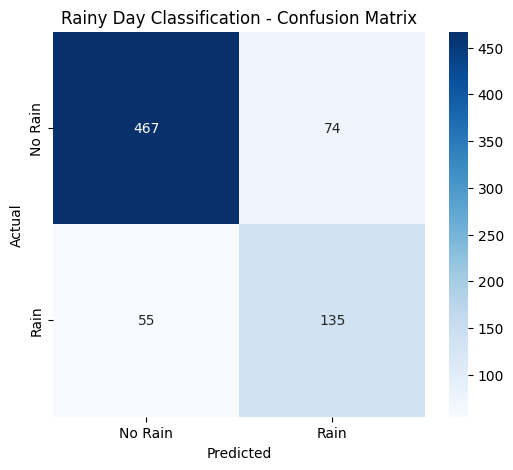

In [1322]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test_class, y_pred_class)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Rain", "Rain"],
    yticklabels=["No Rain", "Rain"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Rainy Day Classification - Confusion Matrix")
plt.savefig("results/figures/rainy_day_confusion_matrix.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [1323]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

baseline_rain = DummyClassifier(strategy="most_frequent")

baseline_rain.fit(X_train_class, y_train_class)

baseline_pred = baseline_rain.predict(X_test_class)

print("Baseline Accuracy:",
      accuracy_score(y_test_class, baseline_pred))

print("Baseline Rain F1-score:",
      f1_score(y_test_class, baseline_pred))

Baseline Accuracy: 0.7400820793433652
Baseline Rain F1-score: 0.0


In [1324]:
df["rainfall_previous_day"] = df["rainfall"].shift(1)
df["rainfall_2_days_ago"] = df["rainfall"].shift(2)

In [1325]:
classification_features = [
    "temp_mean",
    "temp_max",
    "temp_min",
    "rainfall",
    "wind_speed",
    "humidity",
    "month",
    "rainfall_previous_day",
    "rainfall_2_days_ago"
]

In [1326]:
classification_df = df[
    classification_features + [classification_target]
].dropna().copy()

X_class = classification_df[classification_features]
y_class = classification_df[classification_target]

split_index = int(len(classification_df) * 0.8)

X_train_class = X_class.iloc[:split_index]
X_test_class = X_class.iloc[split_index:]

y_train_class = y_class.iloc[:split_index]
y_test_class = y_class.iloc[split_index:]

In [1327]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

rain_model_v2 = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=3,
    random_state=42,
    class_weight="balanced"
)

rain_model_v2.fit(X_train_class, y_train_class)

y_pred_v2 = rain_model_v2.predict(X_test_class)

print("Accuracy:", accuracy_score(y_test_class, y_pred_v2))
print("Precision:", precision_score(y_test_class, y_pred_v2))
print("Recall:", recall_score(y_test_class, y_pred_v2))
print("Rain F1-score:", f1_score(y_test_class, y_pred_v2))

Accuracy: 0.8248974008207934
Precision: 0.6476190476190476
Recall: 0.7157894736842105
Rain F1-score: 0.68


In [1328]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

rain_probabilities = rain_model_v2.predict_proba(X_test_class)[:, 1]

y_pred_threshold = (rain_probabilities >= 0.40).astype(int)

print("Accuracy:", accuracy_score(y_test_class, y_pred_threshold))
print("Precision:", precision_score(y_test_class, y_pred_threshold))
print("Recall:", recall_score(y_test_class, y_pred_threshold))
print("Rain F1-score:", f1_score(y_test_class, y_pred_threshold))

Accuracy: 0.8084815321477428
Precision: 0.59765625
Recall: 0.8052631578947368
Rain F1-score: 0.6860986547085202


In [1329]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    predictions = (rain_probabilities >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test_class, predictions),
        "Recall": recall_score(y_test_class, predictions),
        "F1-score": f1_score(y_test_class, predictions)
    })

threshold_results_df = pd.DataFrame(threshold_results)

threshold_results_df

,Threshold,Precision,Recall,F1-score
0,0.30,0.514019,0.868421,0.645793
1,0.35,0.561837,0.836842,0.672304
2,0.40,0.597656,0.805263,0.686099
3,0.45,0.627706,0.763158,0.688836
4,0.50,0.647619,0.715789,0.680000
5,0.55,0.682796,0.668421,0.675532
6,0.60,0.707317,0.610526,0.655367


In [1330]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
)

logistic_model.fit(X_train_class, y_train_class)

y_pred_logistic = logistic_model.predict(X_test_class)

print("Accuracy:", accuracy_score(y_test_class, y_pred_logistic))
print("Precision:", precision_score(y_test_class, y_pred_logistic))
print("Recall:", recall_score(y_test_class, y_pred_logistic))
print("Rain F1-score:", f1_score(y_test_class, y_pred_logistic))

Accuracy: 0.7729138166894665
Precision: 0.541095890410959
Recall: 0.8315789473684211
Rain F1-score: 0.6556016597510373


In [1331]:
logistic_probabilities = logistic_model.predict_proba(X_test_class)[:, 1]

logistic_threshold_results = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    predictions = (logistic_probabilities >= threshold).astype(int)

    logistic_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test_class, predictions),
        "Recall": recall_score(y_test_class, predictions),
        "F1-score": f1_score(y_test_class, predictions)
    })

pd.DataFrame(logistic_threshold_results)

,Threshold,Precision,Recall,F1-score
0,0.30,0.414692,0.921053,0.571895
1,0.35,0.440506,0.915789,0.594872
2,0.40,0.475783,0.878947,0.617375
3,0.45,0.498471,0.857895,0.630561
4,0.50,0.541096,0.831579,0.655602
5,0.55,0.570896,0.805263,0.668122
6,0.60,0.594017,0.731579,0.655660


In [1332]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

gradient_model = GradientBoostingClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gradient_model.fit(X_train_class, y_train_class)

y_pred_gradient = gradient_model.predict(X_test_class)

print("Accuracy:", accuracy_score(y_test_class, y_pred_gradient))
print("Precision:", precision_score(y_test_class, y_pred_gradient))
print("Recall:", recall_score(y_test_class, y_pred_gradient))
print("Rain F1-score:", f1_score(y_test_class, y_pred_gradient))

Accuracy: 0.8235294117647058
Precision: 0.6848484848484848
Recall: 0.5947368421052631
Rain F1-score: 0.6366197183098592


In [1333]:
gradient_probabilities = gradient_model.predict_proba(X_test_class)[:, 1]

gradient_threshold_results = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50]:
    predictions = (gradient_probabilities >= threshold).astype(int)

    gradient_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test_class, predictions),
        "Recall": recall_score(y_test_class, predictions),
        "F1-score": f1_score(y_test_class, predictions)
    })

pd.DataFrame(gradient_threshold_results)

,Threshold,Precision,Recall,F1-score
0,0.30,0.630252,0.789474,0.700935
1,0.35,0.644144,0.752632,0.694175
2,0.40,0.688442,0.721053,0.704370
3,0.45,0.677966,0.631579,0.653951
4,0.50,0.684848,0.594737,0.636620


## 8. Classification Model Evaluation and Comparison

The classification models were evaluated using precision, recall, F1-score, and the confusion matrix. These metrics help assess how effectively the models identify rainy days while accounting for false predictions.

In [1334]:
model_comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Logistic Regression",
        "Gradient Boosting"
    ],
    "Threshold": [
        0.45,
        0.55,
        0.30
    ],
    "Precision": [
        0.627706,
        0.570896,
        0.630252
    ],
    "Recall": [
        0.763158,
        0.805263,
        0.789474
    ],
    "Rain F1-score": [
        0.688836,
        0.668122,
        0.700935
    ]
})

model_comparison

,Model,Threshold,Precision,Recall,Rain F1-score
0,Random Forest,0.45,0.627706,0.763158,0.688836
1,Logistic Regression,0.55,0.570896,0.805263,0.668122
2,Gradient Boosting,0.30,0.630252,0.789474,0.700935


Rainy Day Classification — Model Comparison

Three classification models were evaluated for predicting whether the next day would be rainy or non-rainy: Random Forest, Logistic Regression, and Gradient Boosting.

Gradient Boosting achieved the highest Rain F1-score of 0.701 at a classification threshold of 0.30. This indicates the best balance between precision and recall for identifying rainy days among the three models.

Random Forest achieved an F1-score of 0.689, while Logistic Regression achieved 0.668. Therefore, Gradient Boosting performed best in this comparison.

The classification threshold affects the balance between false rain predictions and missed rainy days. A lower threshold increases the model's tendency to predict rain, which can improve recall but may reduce precision.

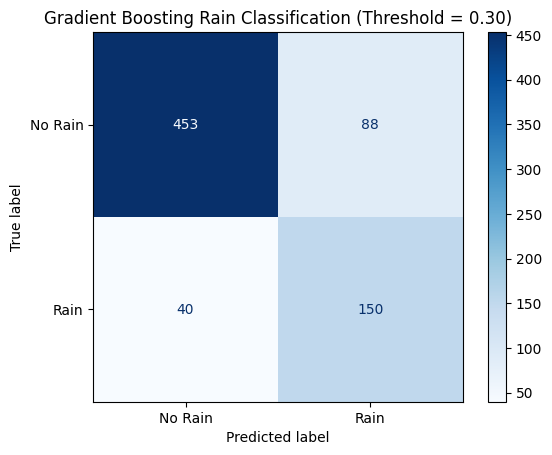

In [1335]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Get probability of rain (class 1)
rain_probabilities = gradient_model.predict_proba(X_test_class)[:, 1]

# Apply the selected threshold
y_pred_gradient_030 = (rain_probabilities >= 0.30).astype(int)

# Create confusion matrix
cm_gradient = confusion_matrix(
    y_test_class,
    y_pred_gradient_030
)

# Plot
display_gradient = ConfusionMatrixDisplay(
    confusion_matrix=cm_gradient,
    display_labels=["No Rain", "Rain"]
)

display_gradient.plot(cmap="Blues")
plt.title("Gradient Boosting Rain Classification (Threshold = 0.30)")
plt.savefig("results/figures/gradient_confusion_matrix.png",
            dpi=300, bbox_inches="tight")
plt.show()

### Interpretation of the Confusion Matrix

The Gradient Boosting classifier was evaluated using a probability threshold of 0.30.

- **453** days were correctly classified as no rain.
- **150** rainy days were correctly identified.
- **88** days were incorrectly predicted as rainy.
- **40** rainy days were incorrectly predicted as no rain.

The model identifies a substantial proportion of rainy days, although some false predictions remain. Lowering the classification threshold makes the model more likely to predict rain, helping it detect more rainy days but also increasing false alarms.

Overall, the confusion matrix shows the model's ability to distinguish rainy and non-rainy days. Its performance should be interpreted using precision, recall, and F1-score alongside accuracy.

### Limitation of Classification Evaluation

Different probability thresholds were explored to examine the trade-off between precision and recall. Since threshold selection was performed using the test results, the reported performance may be optimistic.

In a more rigorous evaluation, the threshold should be selected using a separate validation set, while the test set should be reserved for final evaluation. This is an important consideration when interpreting the classification results.

## 9. Nearby-City Data Extension

To investigate whether weather information from surrounding cities improves temperature forecasting, data from nearby locations was incorporated into the analysis. A combined model was compared with the Mohali-only model using the same chronological evaluation period.

In [1336]:
import pandas as pd
import requests

# Nearby cities and their coordinates
cities = {
    "Chandigarh": (30.7333, 76.7794),
    "Panchkula": (30.6942, 76.8606),
    "Ludhiana": (30.9010, 75.8573),
    "Amritsar": (31.6340, 74.8723)
}

all_city_data = []

for city, (latitude, longitude) in cities.items():
    url = "https://archive-api.open-meteo.com/v1/archive"

    params = {
        "latitude": latitude,
        "longitude": longitude,
        "start_date": "2016-01-01",
        "end_date": "2025-12-31",
        "daily": [
            "temperature_2m_mean",
            "temperature_2m_max",
            "temperature_2m_min",
            "precipitation_sum",
            "wind_speed_10m_max"
        ],
        "timezone": "Asia/Kolkata"
    }

    response = requests.get(url, params=params)
    print(response.status_code)
    print(response.text[:500])

    data = response.json()["daily"]
    city_df = pd.DataFrame(data)

    city_df["city"] = city
    all_city_data.append(city_df)

nearby_cities_df = pd.concat(all_city_data, ignore_index=True)

nearby_cities_df.head()

200
{"latitude":30.75571,"longitude":76.82408,"generationtime_ms":1371.077299118042,"utc_offset_seconds":19800,"timezone":"Asia/Kolkata","timezone_abbreviation":"GMT+5:30","elevation":343.0,"daily_units":{"time":"iso8601","temperature_2m_mean":"°C","temperature_2m_max":"°C","temperature_2m_min":"°C","precipitation_sum":"mm","wind_speed_10m_max":"km/h"},"daily":{"time":["2016-01-01","2016-01-02","2016-01-03","2016-01-04","2016-01-05","2016-01-06","2016-01-07","2016-01-08","2016-01-09","2016-01-10","2
200
{"latitude":30.685411,"longitude":76.83962,"generationtime_ms":404.94024753570557,"utc_offset_seconds":19800,"timezone":"Asia/Kolkata","timezone_abbreviation":"GMT+5:30","elevation":343.0,"daily_units":{"time":"iso8601","temperature_2m_mean":"°C","temperature_2m_max":"°C","temperature_2m_min":"°C","precipitation_sum":"mm","wind_speed_10m_max":"km/h"},"daily":{"time":["2016-01-01","2016-01-02","2016-01-03","2016-01-04","2016-01-05","2016-01-06","2016-01-07","2016-01-08","2016-01-09","201

,time,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,wind_speed_10m_max,city
0,2016-01-01,13.6,21.0,7.7,0.0,8.0,Chandigarh
1,2016-01-02,12.3,20.3,4.8,0.0,12.2,Chandigarh
2,2016-01-03,12.9,21.1,5.8,0.0,16.7,Chandigarh
3,2016-01-04,13.7,20.0,7.6,0.0,6.4,Chandigarh
4,2016-01-05,15.5,22.9,9.9,0.0,9.8,Chandigarh


In [1337]:
nearby_cities_df.to_csv(
    "nearby_cities_weather_2016_2025.csv",
    index=False
)

print(nearby_cities_df.shape)
print(nearby_cities_df["city"].value_counts())

(14612, 7)
city
Chandigarh    3653
Panchkula     3653
Ludhiana      3653
Amritsar      3653
Name: count, dtype: int64


In [1338]:
# Remove the city column from the measurements and reshape
nearby_wide = nearby_cities_df.pivot(
    index="time",
    columns="city",
    values=[
        "temperature_2m_mean",
        "temperature_2m_max",
        "temperature_2m_min",
        "precipitation_sum",
        "wind_speed_10m_max"
    ]
)

# Flatten the column names
nearby_wide.columns = [
    f"{variable}_{city}"
    for variable, city in nearby_wide.columns
]

nearby_wide = nearby_wide.reset_index()

nearby_wide.head()

,time,temperature_2m_mean_Amritsar,temperature_2m_mean_Chandigarh,temperature_2m_mean_Ludhiana,temperature_2m_mean_Panchkula,temperature_2m_max_Amritsar,temperature_2m_max_Chandigarh,temperature_2m_max_Ludhiana,temperature_2m_max_Panchkula,temperature_2m_min_Amritsar,...,temperature_2m_min_Ludhiana,temperature_2m_min_Panchkula,precipitation_sum_Amritsar,precipitation_sum_Chandigarh,precipitation_sum_Ludhiana,precipitation_sum_Panchkula,wind_speed_10m_max_Amritsar,wind_speed_10m_max_Chandigarh,wind_speed_10m_max_Ludhiana,wind_speed_10m_max_Panchkula
0,2016-01-01,13.5,13.6,13.4,13.6,19.9,21.0,21.1,21.0,8.9,...,7.9,7.8,0.0,0.0,0.0,0.0,7.7,8.0,9.4,8.0
1,2016-01-02,12.6,12.3,12.8,12.5,19.6,20.3,20.0,20.3,6.7,...,5.8,5.4,0.0,0.0,0.0,0.0,11.0,12.2,11.2,12.2
2,2016-01-03,13.2,12.9,13.2,13.0,20.4,21.1,20.5,21.2,6.9,...,7.7,5.9,0.0,0.0,0.0,0.0,9.2,16.7,12.1,16.7
3,2016-01-04,13.7,13.7,14.2,13.8,20.1,20.0,20.2,20.2,8.3,...,9.7,7.7,0.8,0.0,0.0,0.0,7.6,6.4,8.4,6.4
4,2016-01-05,14.3,15.5,15.1,15.6,21.5,22.9,22.1,22.9,8.3,...,8.4,10.1,0.0,0.0,0.0,0.0,8.5,9.8,8.9,9.8


In [1339]:
# Convert dates to the same format
nearby_wide["time"] = pd.to_datetime(nearby_wide["time"])
df["date"] = pd.to_datetime(df["date"])

# Merge nearby-city features with Mohali data
weather_extended = df.merge(
    nearby_wide,
    left_on="date",
    right_on="time",
    how="inner"
)

# Remove duplicate date column
weather_extended = weather_extended.drop(columns=["time"])

print(weather_extended.shape)
weather_extended.head()

(3653, 37)


,date,weather_code,temp_mean,temp_max,temp_min,rainfall,wind_speed,humidity,month,year,...,temperature_2m_min_Ludhiana,temperature_2m_min_Panchkula,precipitation_sum_Amritsar,precipitation_sum_Chandigarh,precipitation_sum_Ludhiana,precipitation_sum_Panchkula,wind_speed_10m_max_Amritsar,wind_speed_10m_max_Chandigarh,wind_speed_10m_max_Ludhiana,wind_speed_10m_max_Panchkula
0,2016-01-01,3,13.8,21.4,9.5,0.0,8.0,62,1,2016,...,7.9,7.8,0.0,0.0,0.0,0.0,7.7,8.0,9.4,8.0
1,2016-01-02,3,13.3,21.5,7.5,0.0,12.2,65,1,2016,...,5.8,5.4,0.0,0.0,0.0,0.0,11.0,12.2,11.2,12.2
2,2016-01-03,2,13.4,22.0,8.1,0.0,16.7,69,1,2016,...,7.7,5.9,0.0,0.0,0.0,0.0,9.2,16.7,12.1,16.7
3,2016-01-04,3,13.6,19.1,8.5,0.0,6.4,74,1,2016,...,9.7,7.7,0.8,0.0,0.0,0.0,7.6,6.4,8.4,6.4
4,2016-01-05,3,16.3,24.0,11.7,0.0,9.8,66,1,2016,...,8.4,10.1,0.0,0.0,0.0,0.0,8.5,9.8,8.9,9.8


In [1340]:
# Sort data chronologically
weather_extended = weather_extended.sort_values("date").reset_index(drop=True)

# Check missing values
print("Missing values:", weather_extended.isnull().sum().sum())

# Check date range and dataset size
print("Date range:", weather_extended["date"].min(), "to", weather_extended["date"].max())
print("Shape:", weather_extended.shape)

Missing values: 7
Date range: 2016-01-01 00:00:00 to 2025-12-31 00:00:00
Shape: (3653, 37)


In [1341]:
missing_counts = weather_extended.isnull().sum()

print(missing_counts[missing_counts > 0])

target_temp_next_day     1
temp_previous_day        1
temp_2_days_ago          2
rainfall_previous_day    1
rainfall_2_days_ago      2
dtype: int64


In [1342]:
weather_extended = weather_extended.dropna().reset_index(drop=True)

print("Shape after cleaning:", weather_extended.shape)
print("Missing values remaining:", weather_extended.isnull().sum().sum())

Shape after cleaning: (3650, 37)
Missing values remaining: 0


In [1343]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Target: next-day Mohali mean temperature
target = "target_temp_next_day"

# Use nearby-city weather variables as additional predictors
nearby_features = [
    col for col in weather_extended.columns
    if any(city in col for city in
           ["Chandigarh", "Panchkula", "Ludhiana", "Amritsar"])
]

# Keep the same chronological split as the original model
split_index = int(len(weather_extended) * 0.8)

train_data = weather_extended.iloc[:split_index]
test_data = weather_extended.iloc[split_index:]

X_train = train_data[nearby_features]
X_test = test_data[nearby_features]

y_train = train_data[target]
y_test = test_data[target]

# Train Linear Regression
nearby_model = LinearRegression()
nearby_model.fit(X_train, y_train)

# Predict
nearby_predictions = nearby_model.predict(X_test)

# Evaluate
mae = mean_absolute_error(y_test, nearby_predictions)
rmse = np.sqrt(mean_squared_error(y_test, nearby_predictions))
r2 = r2_score(y_test, nearby_predictions)

print("Nearby-city model results")
print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

Nearby-city model results
MAE: 0.9275973054299071
RMSE: 1.2554542858363011
R²: 0.9700414426566575


In [1344]:
# Match nearby-city data to the original model's dates
model_dates = pd.to_datetime(df.loc[model_df.index, "date"])

weather_extended["date"] = pd.to_datetime(weather_extended["date"])

nearby_for_model = (
    weather_extended
    .set_index("date")
    .reindex(model_dates)
    .reset_index(drop=True)
)

# Select nearby-city weather features
nearby_features = [
    col for col in nearby_for_model.columns
    if any(city in col for city in
           ["Chandigarh", "Panchkula", "Ludhiana", "Amritsar"])
]

# Combine original Mohali features with nearby-city features
X_combined = pd.concat(
    [
        model_df[features].reset_index(drop=True),
        nearby_for_model[nearby_features].reset_index(drop=True)
    ],
    axis=1
)

y_combined = model_df[target].reset_index(drop=True)

print("Combined feature shape:", X_combined.shape)
print("Target shape:", y_combined.shape)
print("Nearby-city features added:", len(nearby_features))
print("Missing values:", X_combined.isnull().sum().sum())

Combined feature shape: (3650, 29)
Target shape: (3650,)
Nearby-city features added: 20
Missing values: 0


In [1345]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Same chronological 80/20 split
split_index = int(len(X_combined) * 0.8)

X_train_combined = X_combined.iloc[:split_index]
X_test_combined = X_combined.iloc[split_index:]

y_train_combined = y_combined.iloc[:split_index]
y_test_combined = y_combined.iloc[split_index:]

# Train model using Mohali + nearby-city features
combined_model = LinearRegression()
combined_model.fit(X_train_combined, y_train_combined)

# Predict next-day temperature
combined_predictions = combined_model.predict(X_test_combined)

# Evaluate
combined_mae = mean_absolute_error(
    y_test_combined, combined_predictions
)
combined_rmse = np.sqrt(
    mean_squared_error(y_test_combined, combined_predictions)
)
combined_r2 = r2_score(
    y_test_combined, combined_predictions
)

print("Mohali + Nearby Cities Model")
print("MAE:", round(combined_mae, 3))
print("RMSE:", round(combined_rmse, 3))
print("R²:", round(combined_r2, 3))

Mohali + Nearby Cities Model
MAE: 0.766
RMSE: 1.056
R²: 0.979


### Effect of Nearby Cities on Temperature Prediction

To investigate whether nearby-city weather data could improve next-day temperature prediction in Mohali, a Linear Regression model was trained using the original Mohali features and an extended set of features from Chandigarh, Panchkula, Ludhiana, and Amritsar.

The models were evaluated using the same chronological 80:20 train-test split.

| Metric | Mohali-only model | Extended model |
|---|---:|---:|
| MAE | 0.773 | 0.766 |
| RMSE | 1.081 | 1.056 |
| R² | 0.978 | 0.979 |

The extended model achieved slightly lower MAE and RMSE and a marginally higher R² score. This suggests that weather conditions in nearby cities provide additional information useful for predicting Mohali's next-day mean temperature.

However, the improvement was small. Therefore, nearby-city data was beneficial in this experiment, but its contribution was limited.

## 10. Data Source and Reproducibility

### Data Source

Historical weather data used in this project was obtained from the Open-Meteo Historical Weather API. The analysis focuses on daily weather observations for Mohali, India, from 2016 to 2025. Weather data from nearby cities was used for the extension.

### Reproducibility

The analysis was performed in Python using Google Colab. The notebook contains the data processing, exploratory analysis, feature engineering, model training, and evaluation steps.

To reproduce the analysis, run the notebook cells in order and ensure that the required datasets are available at the paths specified in the code.

## 11. Overall Conclusion

This project analyzed historical weather patterns in Mohali and developed machine learning models for next-day temperature forecasting and rainfall classification.

Regression models were evaluated using MAE, RMSE, and R². Classification models were assessed using precision, recall, F1-score, and confusion matrices.

The nearby-city extension investigated whether weather data from surrounding locations could improve temperature prediction. The combined model showed a modest improvement over the Mohali-only model in this experiment.

Overall, the project demonstrates how historical weather data and machine learning can be used to study weather patterns and support short-term weather prediction. Future work could include testing additional features, evaluating models on a separate validation period, and incorporating more weather observations.

## 12. Predicted vs. Actual Next-Day Weather

This section compares the model's predicted next-day weather values
with the actual observed weather in the test dataset.

In [1346]:
# Compare actual and predicted next-day temperatures
temperature_comparison = pd.DataFrame({
    "Date": df.loc[model_df.index, "date"].iloc[
        int(len(model_df) * 0.8):
    ].reset_index(drop=True),
    "Actual Temperature (°C)": y_test.reset_index(drop=True),
    "Predicted Temperature (°C)": linear_predictions
})

# Calculate prediction error
temperature_comparison["Error (°C)"] = (
    temperature_comparison["Predicted Temperature (°C)"]
    - temperature_comparison["Actual Temperature (°C)"]
)

# Display first 10 comparisons
temperature_comparison.head(10).round(2)

,Date,Actual Temperature (°C),Predicted Temperature (°C),Error (°C)
0,2024-01-01,11.6,11.89,0.29
1,2024-01-02,11.6,11.61,0.01
2,2024-01-03,10.5,11.78,1.28
3,2024-01-04,10.0,10.60,0.60
4,2024-01-05,10.2,10.03,-0.17
5,2024-01-06,10.8,10.67,-0.13
6,2024-01-07,10.4,10.61,0.21
7,2024-01-08,10.3,10.65,0.35
8,2024-01-09,10.5,10.56,0.06
9,2024-01-10,9.7,10.39,0.69


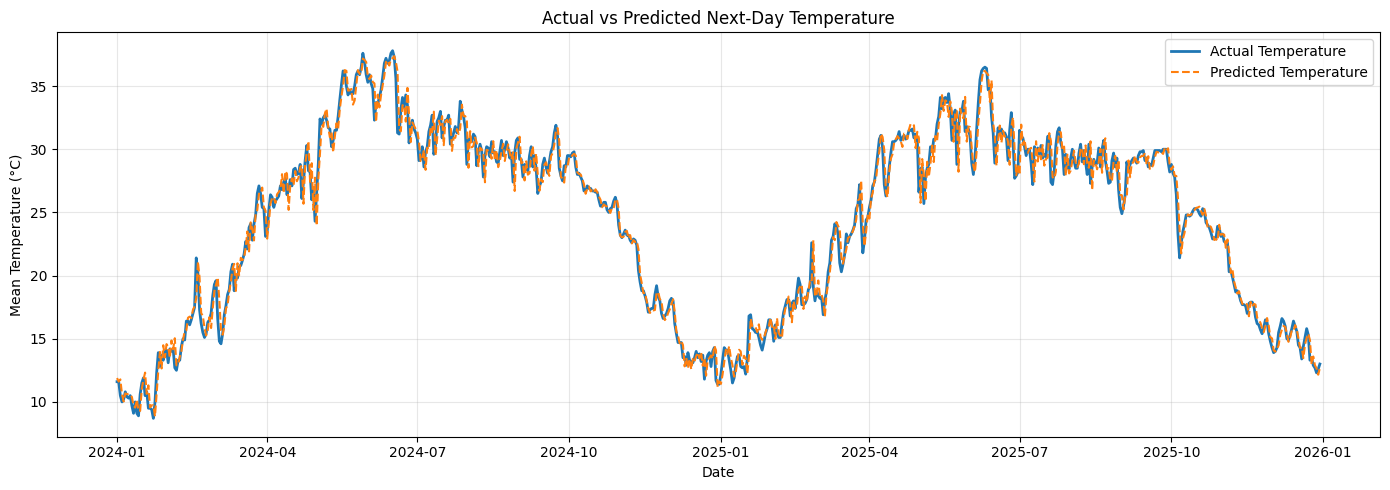

In [1347]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    temperature_comparison["Date"],
    temperature_comparison["Actual Temperature (°C)"],
    label="Actual Temperature",
    linewidth=2
)

plt.plot(
    temperature_comparison["Date"],
    temperature_comparison["Predicted Temperature (°C)"],
    label="Predicted Temperature",
    linestyle="--"
)

plt.title("Actual vs Predicted Next-Day Temperature")
plt.xlabel("Date")
plt.ylabel("Mean Temperature (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("results/figures/actual_vs_predicted_temperature.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [1348]:
print("Gradient Boosting model features:")
print(gradient_model.feature_names_in_)

print("\nClassification test variables:")
for name in ["X_test_class", "y_test_class", "X_test", "y_test"]:
    if name in globals():
        print(name, "exists")

Gradient Boosting model features:
['temp_mean' 'temp_max' 'temp_min' 'rainfall' 'wind_speed' 'humidity'
 'month' 'rainfall_previous_day' 'rainfall_2_days_ago']

Classification test variables:
X_test_class exists
y_test_class exists
X_test exists
y_test exists


In [1349]:
# Predict rainfall probability for the classification test dataset
rain_probabilities = gradient_model.predict_proba(X_test_class)[:, 1]

# Apply the selected threshold of 0.30
rain_predictions = (rain_probabilities >= 0.30).astype(int)

# Create the comparison table
rainfall_comparison = pd.DataFrame({
    "Actual Rainfall": y_test_class.reset_index(drop=True),
    "Predicted Rainfall": rain_predictions,
    "Rain Probability (%)": rain_probabilities * 100
})

# Convert labels into readable categories
rainfall_comparison["Actual Weather"] = (
    rainfall_comparison["Actual Rainfall"]
    .map({0: "No Rain", 1: "Rainy"})
)

rainfall_comparison["Predicted Weather"] = (
    rainfall_comparison["Predicted Rainfall"]
    .map({0: "No Rain", 1: "Rainy"})
)

# Display the first 10 comparisons
rainfall_comparison.head(10).round(2)

,Actual Rainfall,Predicted Rainfall,Rain Probability (%),Actual Weather,Predicted Weather
0,0,0,14.11,No Rain,No Rain
1,0,0,9.74,No Rain,No Rain
2,0,0,10.18,No Rain,No Rain
3,0,0,10.18,No Rain,No Rain
4,0,0,8.11,No Rain,No Rain
5,0,0,5.32,No Rain,No Rain
6,0,0,10.18,No Rain,No Rain
7,0,0,7.52,No Rain,No Rain
8,0,0,6.61,No Rain,No Rain
9,0,0,6.26,No Rain,No Rain


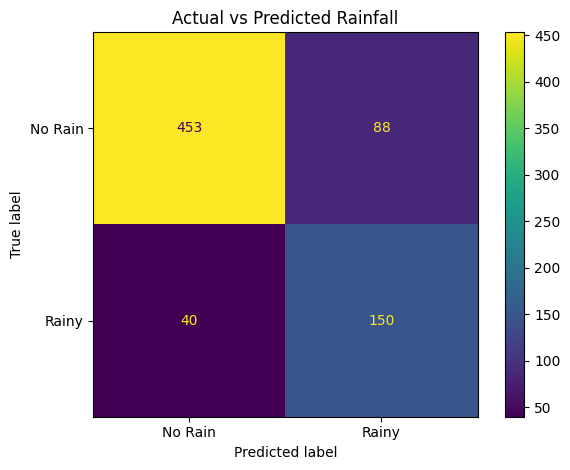

In [1350]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate the confusion matrix
cm = confusion_matrix(
    y_test_class,
    rain_predictions
)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Rain", "Rainy"]
)

disp.plot()
plt.title("Actual vs Predicted Rainfall")
plt.tight_layout()
plt.savefig("results/figures/actual_vs_predicted_rainfall.png",
            dpi=300, bbox_inches="tight")
plt.show()

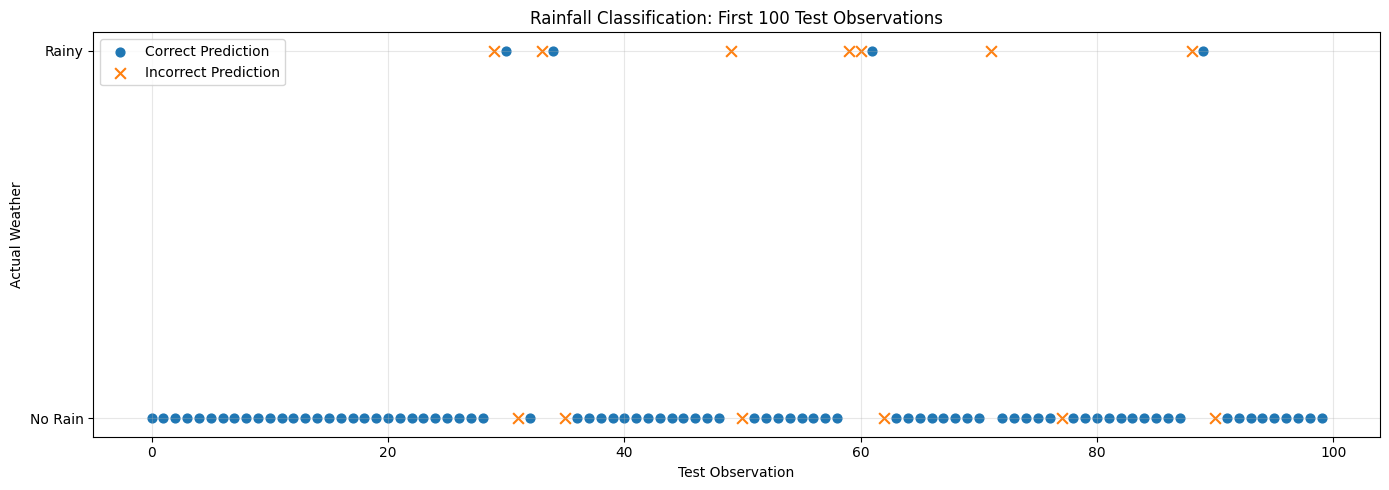

In [1351]:
import matplotlib.pyplot as plt
import numpy as np

actual = np.array(y_test_class)
predicted = np.array(rain_predictions)

# Show only the first 100 test observations
n = 100
correct = actual[:n] == predicted[:n]
incorrect = actual[:n] != predicted[:n]

plt.figure(figsize=(14, 5))

plt.scatter(
    np.where(correct)[0],
    actual[:n][correct],
    label="Correct Prediction",
    marker="o",
    s=40
)

plt.scatter(
    np.where(incorrect)[0],
    actual[:n][incorrect],
    label="Incorrect Prediction",
    marker="x",
    s=60
)

plt.title("Rainfall Classification: First 100 Test Observations")
plt.xlabel("Test Observation")
plt.ylabel("Actual Weather")
plt.yticks([0, 1], ["No Rain", "Rainy"])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("results/figures/rainfall_classification.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [1352]:
from sklearn.metrics import classification_report

# Evaluate rainfall classification on the full test dataset
report = classification_report(
    y_test_class,
    rain_predictions,
    target_names=["No Rain", "Rainy"],
    zero_division=0
)

print("Rainfall Classification Report")
print(report)

Rainfall Classification Report
              precision    recall  f1-score   support

     No Rain       0.92      0.84      0.88       541
       Rainy       0.63      0.79      0.70       190

    accuracy                           0.82       731
   macro avg       0.77      0.81      0.79       731
weighted avg       0.84      0.82      0.83       731



### Interpretation of Rainfall Classification Results

The Gradient Boosting classifier achieved an accuracy of approximately 82% on the test dataset.

The model performed better in identifying non-rainy days, with an F1-score of 0.88. For rainy days, it achieved a precision of 0.63, recall of 0.79, and F1-score of 0.70.

The rainy-day recall indicates that the model detected approximately 79% of the actual rainy days in the test dataset. However, its lower precision indicates that some predicted rainy days did not experience rainfall.

Overall, the model is better at identifying non-rainy days than rainy days. This may be influenced by the imbalance between the number of rainy and non-rainy observations.

## 13. Next-Day Weather Prediction Demonstration

This section demonstrates how the trained machine learning models can
predict the next day's weather using the most recent available weather
observations.

In [1353]:
# Check the latest available weather observation
df[["date", "temp_mean", "temp_max", "temp_min",
    "rainfall", "wind_speed", "humidity"]].tail()

,date,temp_mean,temp_max,temp_min,rainfall,wind_speed,humidity
3648,2025-12-27,12.9,19.5,8.9,0.0,11.7,88
3649,2025-12-28,12.7,19.2,9.0,0.0,8.7,85
3650,2025-12-29,12.3,17.9,9.3,0.0,9.0,89
3651,2025-12-30,12.6,18.4,9.2,0.0,8.8,90
3652,2025-12-31,13.0,16.2,10.6,0.0,15.5,83


In [1354]:
# Get the most recent available weather observation
latest_weather = df.iloc[[-1]]

# Select the same features used during model training
latest_features = latest_weather[features]

# Predict next-day mean temperature
predicted_temperature = linear_model.predict(latest_features)[0]

# Get the date for the prediction
prediction_date = pd.to_datetime(
    latest_weather["date"].iloc[0]
) + pd.Timedelta(days=1)

print("Prediction date:", prediction_date.strftime("%Y-%m-%d"))
print(
    "Predicted next-day mean temperature:",
    round(predicted_temperature, 2),
    "°C"
)

Prediction date: 2026-01-01
Predicted next-day mean temperature: 12.82 °C


In [1355]:
# Prepare the latest observation for rainfall prediction
latest_rain_features = latest_weather[classification_features]

# Predict the probability of rain
rain_probability = gradient_model.predict_proba(
    latest_rain_features
)[0, 1]

# Apply the selected threshold (0.30)
predicted_rain = int(rain_probability >= 0.30)

# Display the result
print("Prediction date:", prediction_date.strftime("%Y-%m-%d"))
print("Probability of rain:", round(rain_probability * 100, 2), "%")

if predicted_rain == 1:
    print("Predicted next-day weather: Rainy")
else:
    print("Predicted next-day weather: No rain")

Prediction date: 2026-01-01
Probability of rain: 3.15 %
Predicted next-day weather: No rain


In [1356]:
# Combined next-day weather prediction summary

print("=" * 40)
print("NEXT-DAY WEATHER PREDICTION")
print("=" * 40)

print("Location: Mohali")
print("Prediction date:", prediction_date.strftime("%Y-%m-%d"))

print(
    "Predicted mean temperature:",
    round(predicted_temperature, 2),
    "°C"
)

print(
    "Rain probability:",
    round(rain_probability * 100, 2),
    "%"
)

print(
    "Rainfall classification:",
    "Rainy" if predicted_rain == 1 else "No Rain"
)

print("=" * 40)

NEXT-DAY WEATHER PREDICTION
Location: Mohali
Prediction date: 2026-01-01
Predicted mean temperature: 12.82 °C
Rain probability: 3.15 %
Rainfall classification: No Rain


In [1357]:
!zip -r results.zip results

updating: results/ (stored 0%)
updating: results/figures/ (stored 0%)
updating: results/figures/average_monthly_maximum_wind_speed_in_mohali.png (deflated 15%)
updating: results/figures/monthly_temperature.png (deflated 14%)
updating: results/figures/actual_vs_predicted_temperature.png (deflated 7%)
updating: results/figures/average_temperature_by_season.png (deflated 23%)
updating: results/figures/correlation_between_weather_variables_in_mohali.png (deflated 13%)
updating: results/figures/rainy_day_confusion_matrix.png (deflated 20%)
updating: results/figures/average_monthly_rainfall_in_mohali.png (deflated 15%)
updating: results/figures/actual_vs_predicted_rainfall.png (deflated 21%)
updating: results/figures/daily_rainfall_distribution.png (deflated 27%)
updating: results/figures/average_monthly_maximum_and_minimum_temperature_in_mohali.png (deflated 11%)
updating: results/figures/rainfall_classification.png (deflated 31%)
updating: results/figures/average_monthly_temperature_in_moh

In [1358]:
from google.colab import files
files.download("results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1359]:
import os

for root, dirs, files in os.walk("results"):
    print(root, files)

results []
results/figures ['average_monthly_maximum_wind_speed_in_mohali.png', 'monthly_temperature.png', 'actual_vs_predicted_temperature.png', 'average_temperature_by_season.png', 'correlation_between_weather_variables_in_mohali.png', 'rainy_day_confusion_matrix.png', 'average_monthly_rainfall_in_mohali.png', 'actual_vs_predicted_rainfall.png', 'daily_rainfall_distribution.png', 'average_monthly_maximum_and_minimum_temperature_in_mohali.png', 'rainfall_classification.png', 'average_monthly_temperature_in_mohali.png', 'gradient_confusion_matrix.png', 'yearly_temperature_in_mohali.png', 'average_monthly_humidity_in_mohali.png']
